## **DATA VERIFICATION**

In [1]:
!python scripts/01_verify_dataset.py


CerviFusion Dataset Verification (CROPPED images)
Dataset root: D:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\dataset\main
Total BMP files found: 4049
Valid images:          4049
Corrupted/unreadable:  0

Per-class counts:
  Dyskeratotic                   813
  Koilocytotic                   825
  Metaplastic                    793
  Parabasal                      787
  Superficial-Intermediate       831

Image dimensions:
  Width  -> min: 62, max: 531, avg: 214.7
  Height -> min: 48, max: 553, avg: 191.0

Color modes:
  RGB: 4049

Slide-level grouping (for split planning):
  Dyskeratotic                   223 unique slides
  Koilocytotic                   238 unique slides
  Metaplastic                    271 unique slides
  Parabasal                      108 unique slides
  Superficial-Intermediate       126 unique slides

Duplicate filenames across classes: 1089
  001_01.bmp -> ['dataset\\main\\im_Dyskeratotic\\im_Dyskeratotic\\CROPPED


Verifying images: 100%|██████████| 4049/4049 [00:26<00:00, 153.55it/s]


In [2]:
!nvidia-smi

Fri Nov 13 11:34:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 591.74                 Driver Version: 591.74         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 2060      WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   75C    P8              8W /  115W |     339MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# **Data Splitting**

In [3]:
!python scripts/02_create_split.py


SPLIT RESULT (exact image counts)
  train : 2851 images   (70.412448% of 4049)
  val   : 599 images   (14.793776% of 4049)
  test  : 599 images   (14.793776% of 4049)
  total : 4049 images   (must equal 4049)
  target: train 70% | val 15% | test 15%
  method: slide_groups_image_balanced | seed: 42

Slide groups (exact):
  train : 681
  val   : 138
  test  : 147
  total : 966

Slide leakage:
  OK (966 groups, 0 leaked)

Per-class image counts (exact):
       Dysk Koil Meta Para  S-I
  train:  585  576  555  553  582
  val  :  114  124  119  115  127
  test :  114  125  119  119  122

Wrote CSVs under: results\splits/
JSON summary: results\splits\split_summary.json


# **Training in Progress**

In [ ]:
!python  scripts/03_train_cervifusion.py

Device: cuda
Model: CerviFusion -> EN=efficientnet_b0, ViT=vit_small_patch16_224, fusion_dim=512, heads=4
Training config -> image_size=224, batch_size=4, epochs=20, lr=0.0001
Local pretrained weights -> EN=checkpoints/pretrained/efficientnet_b0.pth, ViT=checkpoints/pretrained/vit_small_patch16_224.pth
Dataset sizes -> train=2851, val=599, test=599
Loaded local pretrained weights: /content/drive/MyDrive/CervicalFusion-TR/CervicalFusion/checkpoints/pretrained/efficientnet_b0.pth
Loaded local pretrained weights: /content/drive/MyDrive/CervicalFusion-TR/CervicalFusion/checkpoints/pretrained/vit_small_patch16_224.pth
Total parameters: 27,713,025

Epoch 1/20
  train loss=0.6993, acc=0.7439 | val loss=0.6399, acc=0.7462
  Saved new best model (val acc=0.7462)

Epoch 2/20
  train loss=0.4047, acc=0.8608 | val loss=0.2694, acc=0.9115
  Saved new best model (val acc=0.9115)

Epoch 3/20
  train loss=0.3281, acc=0.8948 | val loss=0.2580, acc=0.9165
  Saved new best model (val acc=0.9165)

Epoch 4

# **Training Log Graph**

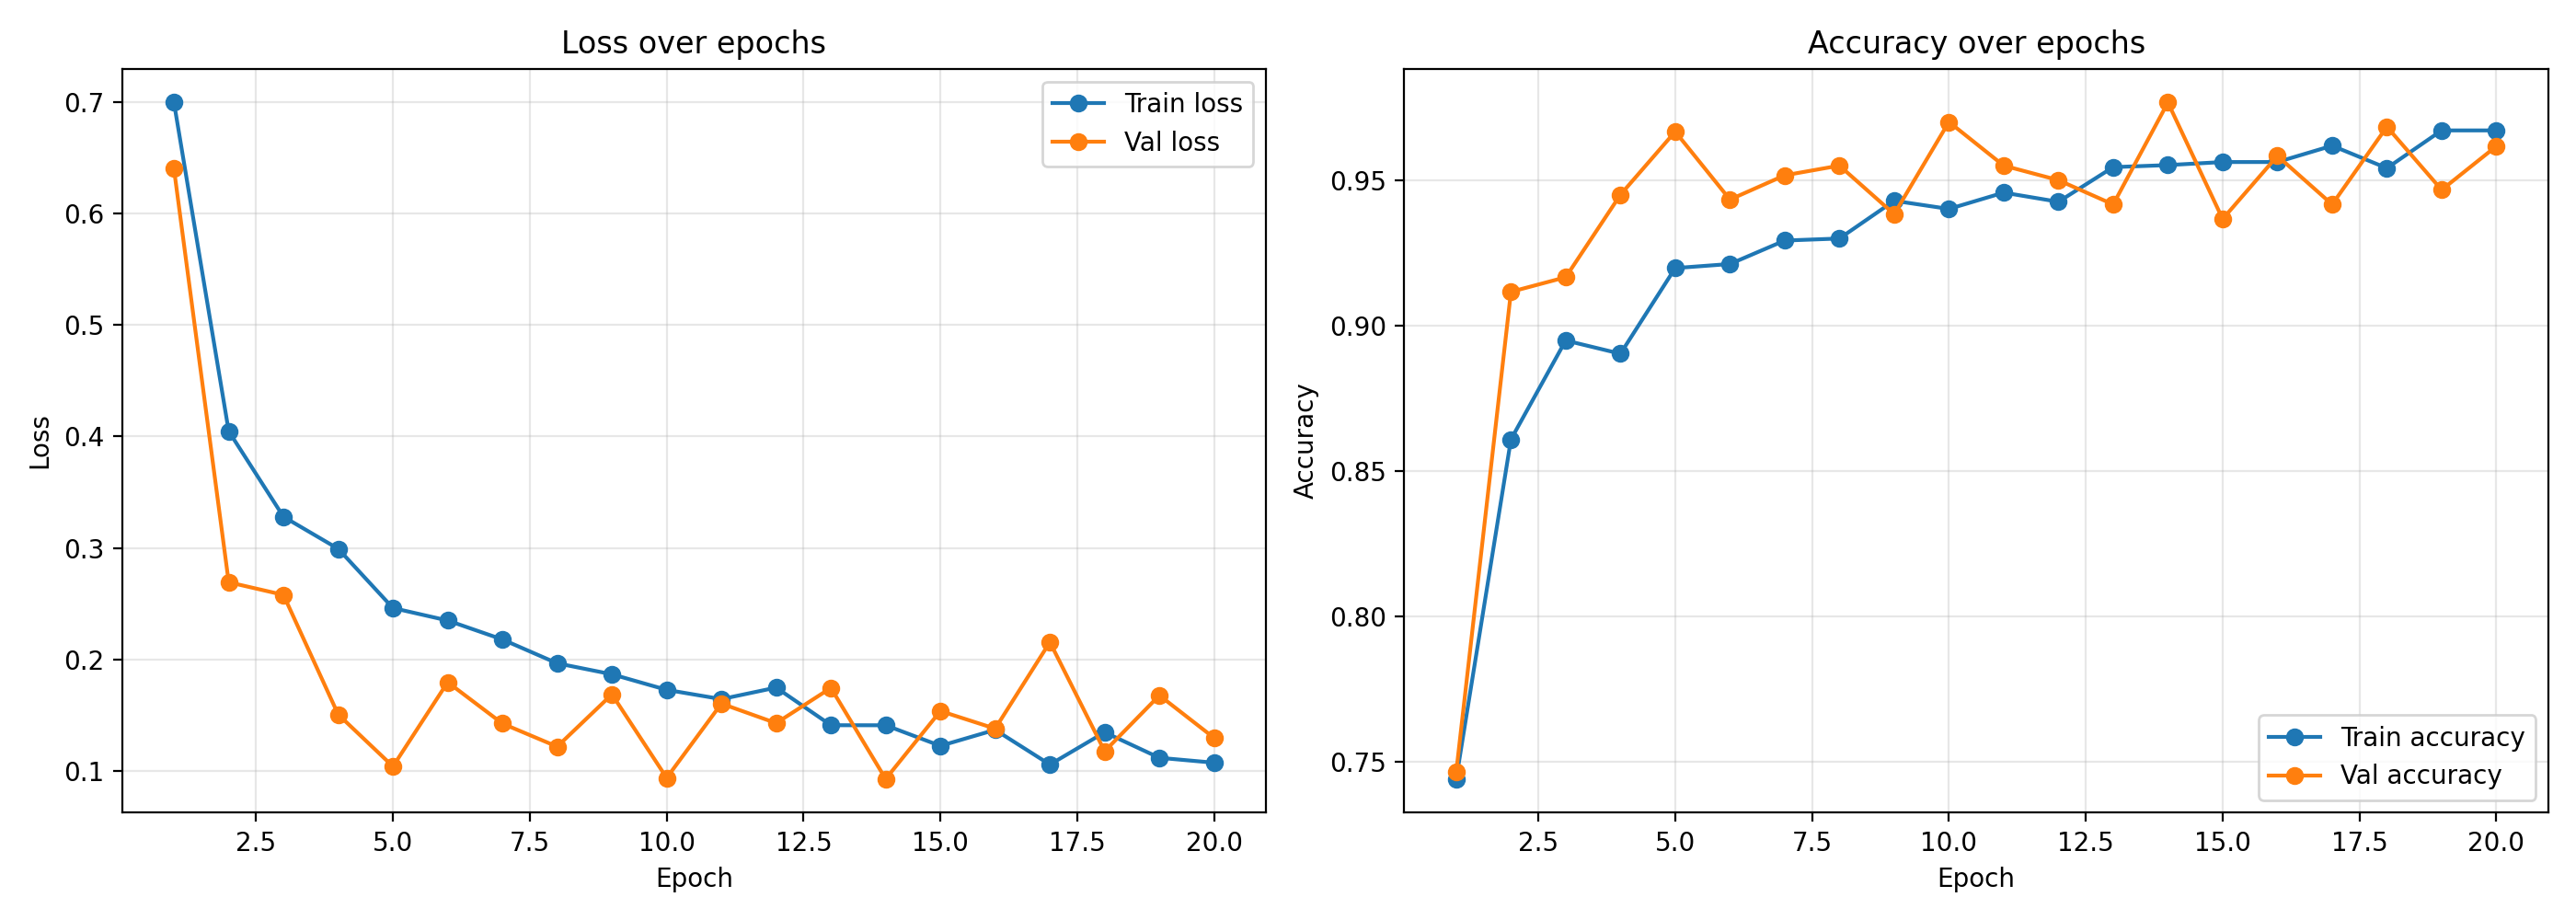

In [7]:
from pathlib import Path
from IPython.display import Image, display

image_path = Path.cwd() / "results" / "metrics" / "cervifusion" / "training_history.png"
display(Image(filename=str(image_path)))

# **Metric Analysis**

In [9]:
!pip install matplotlib scikit-learn seaborn

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------ --------------------------------- 1.8/11.3 MB 12.6 MB/s eta 0:00:01
   ------------ --------------------------- 3.7/11.3 MB 12.1 MB/s eta 0:00:01
   ----------------- ---------------------- 5.0/11.3 MB 8.4 MB/s eta 0:00:01
   ---------------------- ----------------- 6.3/11.3 MB 8.0 MB/s eta 0:00:01
   ------------------------ --------------- 6.8/11.3 MB 7.4 MB/s eta 0:00:01
   -------------------------- ------------- 7.6/11.3 MB 6.2 MB/s eta 0:00:01
   ------------------------------ --------- 8.7/11.3 MB 6.1 MB/s eta 0:00:01
   ----------------------------------- ---- 10.0/11.3 MB 6.1 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.3 MB 6.1 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 6.0 MB/s  0:00:01

   ---------------------------------------- 0/4 [pytz]
   ---------------------------------------- 0/4 [pytz]
   ---------------------------------------- 0/4

In [10]:
!python -m scripts.analyse --split test

Device: cuda
Checkpoint: D:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\checkpoints\cervifusion\best_model.pt

TEST
 Accuracy:       0.9048
 Precision:      0.9127
 Recall:         0.9052
 Specificity:    0.9761
 F1:             0.9078
 Cohen kappa:    0.8810
 class                            prec   recall     spec       f1
 Dyskeratotic                   0.9815   0.9298   0.9959   0.9550
 Koilocytic                     0.8195   0.8720   0.9494   0.8450
 Metaplastic                    0.7803   0.8655   0.9396   0.8207
 Parabasal                      0.9910   0.9244   0.9979   0.9565
 Superficial-Intermediate       0.9913   0.9344   0.9979   0.9620

Confusion matrix saved to D:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\results\analysis\cervifusion\confusion_matrix.png


# **Confusion Matrix**

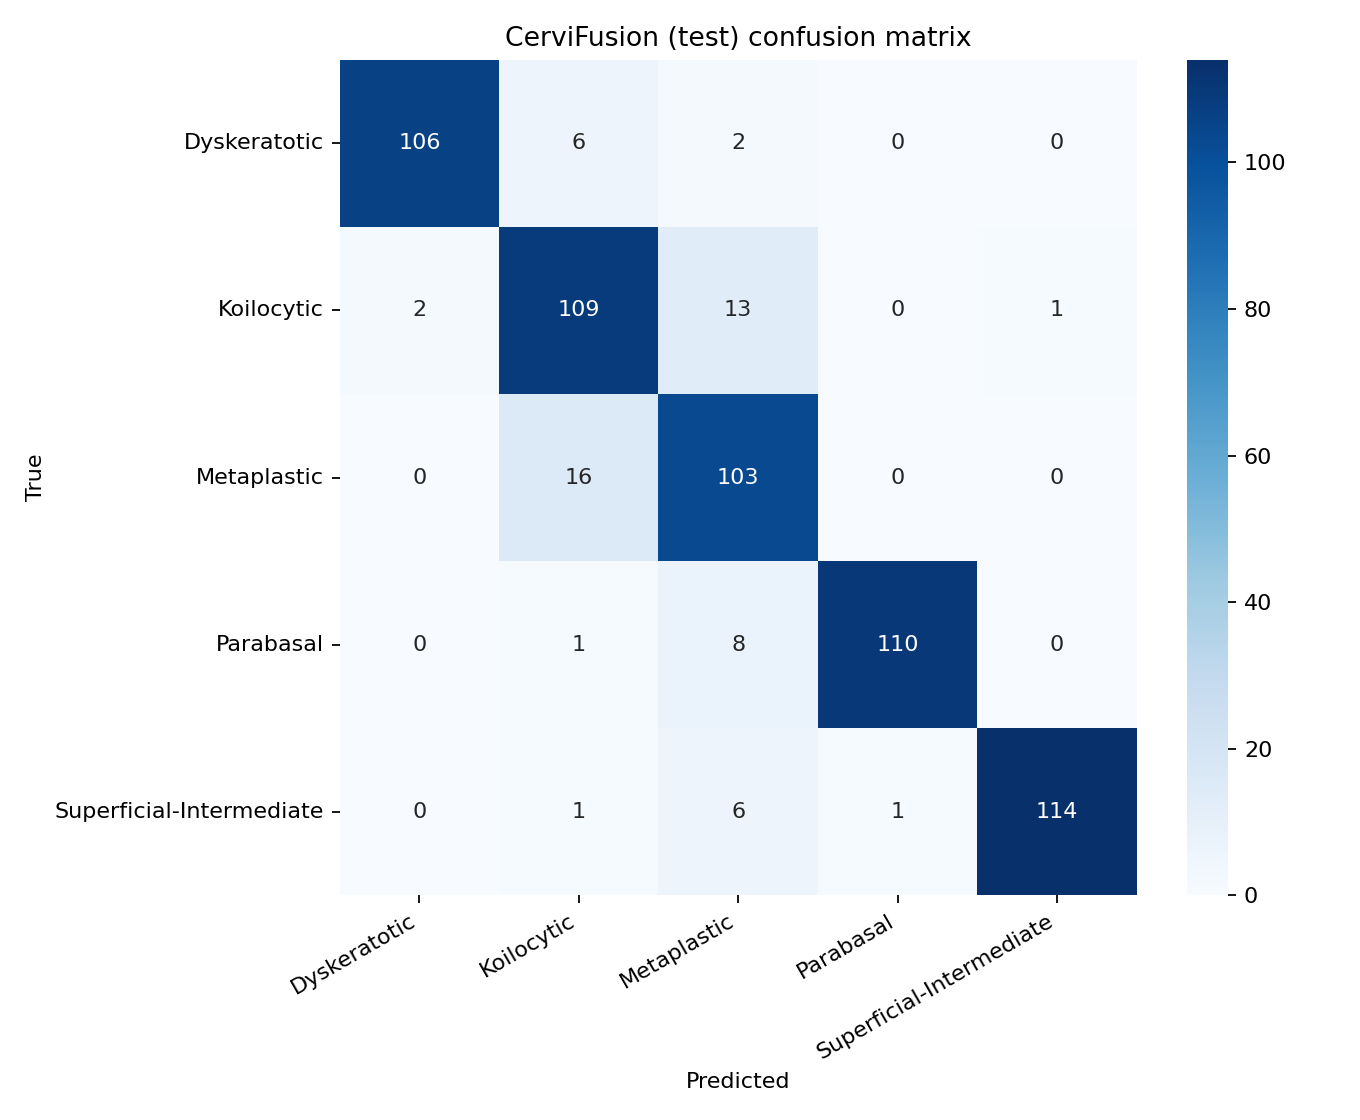

In [11]:
from pathlib import Path
from IPython.display import Image, display

image_path = Path.cwd() / "results" / "analysis" / "cervifusion" / "confusion_matrix.png"
display(Image(filename=str(image_path)))

c:\Users\Manuel\anaconda3\envs\cervifusion\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


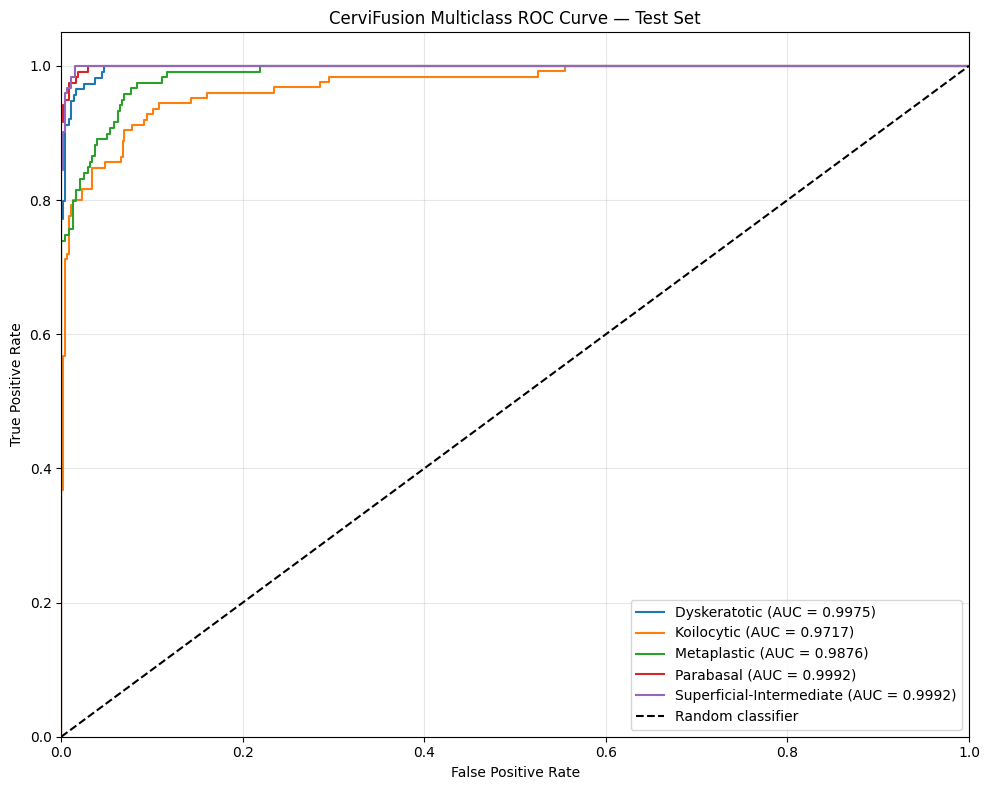


Test samples: 599
ROC curve saved to: D:\ExcellencProject\2026\CervicalFusion\CervicalFusion-20261112T164414Z-1-001\CervicalFusion\results\analysis\cervifusion\roc_curve.png
Macro-average AUC: 0.9910
Macro OvR AUC: 0.9910


In [12]:
# ============================================================
# CerviFusion: Multiclass ROC Curve and AUC
# Uses the existing project model, checkpoint and test dataloader
# ============================================================

import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Find project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").is_dir():
    candidates = [
        Path("/content/drive/MyDrive/CervicalFusion-TR/CervicalFusion"),
        Path("/content/CervicalFusion-TR/CervicalFusion"),
    ]
    PROJECT_ROOT = next(
        (p for p in candidates if (p / "src").is_dir()),
        PROJECT_ROOT
    )

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError(
        "Project root not found. Set PROJECT_ROOT to your CerviFusion "
        "project directory."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.constants import CLASS_NAMES, PROJECT_ROOT as ROOT
from src.dataset.dataloaders import create_dataloaders
from src.models.cervifusion import create_cervifusion

# Load the same checkpoint used by analyse.py
checkpoint_path = ROOT / "checkpoints" / "cervifusion" / "best_model.pt"

if not checkpoint_path.exists():
    raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

try:
    checkpoint = torch.load(
        checkpoint_path, map_location=device, weights_only=False
    )
except TypeError:
    checkpoint = torch.load(checkpoint_path, map_location=device)

# Use the saved training configuration
config = checkpoint.get("config")

if not isinstance(config, dict) or not config:
    import yaml
    config_path = ROOT / "configs" / "cervifusion_cpu_light.yaml"
    with config_path.open(encoding="utf-8") as f:
        config = yaml.safe_load(f)

model = create_cervifusion(
    efficientnet_name=config.get("efficientnet_name", "efficientnet_b0"),
    vit_name=config.get("vit_name", "vit_small_patch16_224"),
    pretrained=False,
    fusion_dim=int(config.get("fusion_dim", 512)),
    num_heads=int(config.get("fusion_heads", 4)),
    dropout=float(config.get("dropout", 0.3)),
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

# Create the test dataloader using the project configuration
splits_dir = Path(config.get("splits_dir", "results/splits"))
if not splits_dir.is_absolute():
    splits_dir = ROOT / splits_dir

dataloaders = create_dataloaders(
    image_size=int(config.get("image_size", 224)),
    batch_size=int(config.get("batch_size", 4)),
    num_workers=int(config.get("num_workers", 0)),
    splits_dir=splits_dir,
)

# Collect actual labels and predicted probabilities
y_true_list = []
y_prob_list = []

with torch.no_grad():
    for batch in dataloaders["test"]:
        # Assumes the dataloader returns (images, labels)
        images, labels = batch[0], batch[1]
        images = images.to(device)

        outputs = model(images)

        # Handle models that return a dictionary or tuple
        if isinstance(outputs, dict):
            outputs = outputs.get("logits", outputs.get("output"))
        elif isinstance(outputs, (tuple, list)):
            outputs = outputs[0]

        if outputs is None or outputs.ndim != 2:
            raise ValueError("Could not obtain classification logits from model.")

        probabilities = torch.softmax(outputs, dim=1)

        y_true_list.extend(labels.cpu().numpy().tolist())
        y_prob_list.extend(probabilities.cpu().numpy().tolist())

y_true = np.asarray(y_true_list, dtype=int)
y_prob = np.asarray(y_prob_list)

num_classes = len(CLASS_NAMES)

if y_prob.shape[1] != num_classes:
    raise ValueError(
        f"Model returned {y_prob.shape[1]} outputs, "
        f"but CLASS_NAMES contains {num_classes} classes."
    )

# One-vs-rest ROC
y_true_binary = label_binarize(
    y_true, classes=np.arange(num_classes)
)

plt.figure(figsize=(10, 8))
class_aucs = []

for i, class_name in enumerate(CLASS_NAMES):
    if len(np.unique(y_true_binary[:, i])) < 2:
        print(f"Skipping {class_name}: only one label outcome in test data.")
        continue

    fpr, tpr, _ = roc_curve(
        y_true_binary[:, i], y_prob[:, i]
    )
    class_auc = auc(fpr, tpr)
    class_aucs.append(class_auc)

    plt.plot(
        fpr, tpr,
        label=f"{class_name} (AUC = {class_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CerviFusion Multiclass ROC Curve — Test Set")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()

output_dir = ROOT / "results" / "analysis" / "cervifusion"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "roc_curve.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"\nTest samples: {len(y_true)}")
print(f"ROC curve saved to: {output_path}")

if class_aucs:
    print(f"Macro-average AUC: {np.mean(class_aucs):.4f}")

    try:
        macro_auc = roc_auc_score(
            y_true, y_prob,
            labels=np.arange(num_classes),
            multi_class="ovr",
            average="macro"
        )
        print(f"Macro OvR AUC: {macro_auc:.4f}")
    except ValueError as e:
        print(f"Macro OvR AUC could not be calculated: {e}")